# Fundamentos de mineração de dados e ciência de dados

## Desempenho e avaliação - 27/10
**Brener Gomes dos Santos**

Exercícios:

Considere o conjunto de dados sobre o molusco Abalone, que pode ser encontrado
na página: https://archive.ics.uci.edu/dataset/1/abalone.

In [ ]:
!pip install ucimlrepo

In [ ]:
from ucimlrepo import fetch_ucirepo

# fetch dataset
abalone = fetch_ucirepo(id=1)

# data (as pandas dataframes)
X = abalone.data.features
y = abalone.data.targets

# metadata
print(abalone.metadata)

# variable information
print(abalone.variables)

{'uci_id': 1, 'name': 'Abalone', 'repository_url': 'https://archive.ics.uci.edu/dataset/1/abalone', 'data_url': 'https://archive.ics.uci.edu/static/public/1/data.csv', 'abstract': 'Predict the age of abalone from physical measurements', 'area': 'Biology', 'tasks': ['Classification', 'Regression'], 'characteristics': ['Tabular'], 'num_instances': 4177, 'num_features': 8, 'feature_types': ['Categorical', 'Integer', 'Real'], 'demographics': [], 'target_col': ['Rings'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1994, 'last_updated': 'Mon Aug 28 2023', 'dataset_doi': '10.24432/C55C7W', 'creators': ['Warwick Nash', 'Tracy Sellers', 'Simon Talbot', 'Andrew Cawthorn', 'Wes Ford'], 'intro_paper': None, 'additional_info': {'summary': 'Predicting the age of abalone from physical measurements.  The age of abalone is determined by cutting the shell through the cone, staining it, and counting the number of rings through a microscope -- 

- **Escolha uma variável dependente, alvo de seu modelo de predição.**
  - A variável escolhida será Rings.
- **Escolha as variáveis dependentes que queira usar em seu modelo.**
  - As outras variáveis serão 'Length', 'Height' e 'Diameter'.
- **Formule o problema como regressão ou classificação, conforme sua preferência.**
  - O problema será formulado como regressão.
- **Escolha então uma medida de desempenho adequada à sua variável dependente e ao seu problema. Justifique sua escolha.**
  - Será utilizado o mean squared error. Para quantificar a diferença média entre os valores que serão previstos pelo modelo de regreção e os valores reais observados no conjunto de dados.


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.ensemble import RandomForestRegressor
from sklearn import tree
import numpy as np
import pandas as pd

- **Separe o conjunto de dados em treino e teste. Cuidado com vazamentos, se
for fazer pré-processamento! Faça o pré-processamento somente após a divisão.**


In [ ]:
# Codifica a variável categórica 'Sex' usando one-hot encoding
X_encoded = pd.get_dummies(X, columns=['Sex'], drop_first=True)

# Selecionar as outras variáveis independentes de X_encoded
X_selected = X_encoded[['Length', 'Height', 'Diameter', 'Sex_I', 'Sex_M']]

# Separar o conjunto de dados em treino e teste (80% treino, 20% teste)
X_train, X_test, y_train, y_test = train_test_split(X_selected, y, test_size=0.2, random_state=42)

print("Tamanho do conjunto de treino (X_train):", X_train.shape)
print("Tamanho do conjunto de teste (X_test):", X_test.shape)
print("Tamanho do conjunto de treino (y_train):", y_train.shape)
print("Tamanho do conjunto de teste (y_test):", y_test.shape)

Tamanho do conjunto de treino (X_train): (3341, 5)
Tamanho do conjunto de teste (X_test): (836, 5)
Tamanho do conjunto de treino (y_train): (3341, 1)
Tamanho do conjunto de teste (y_test): (836, 1)


- **Treine seu modelo no conjunto de treino e teste-o no de teste (com os
hiperparâmetros de sua escolha, fixos e arbitrários)**

In [ ]:
# Iniciando o modelo Random Forest Regressor
model = RandomForestRegressor(random_state=42)

# Treina o modelo com os dados de treino
model.fit(X_train, y_train.values.ravel())

# Faz as previsões no conjunto de teste
y_pred = model.predict(X_test)

# Avalia o modelo usando Mean Squared Error (MSE)
mse = mean_squared_error(y_test, y_pred)

print(f"MSE: {mse}")

MSE: 7.66485217118019


- **Construa a curva de aprendizagem de seu modelo nos subconjuntos de
teste.**

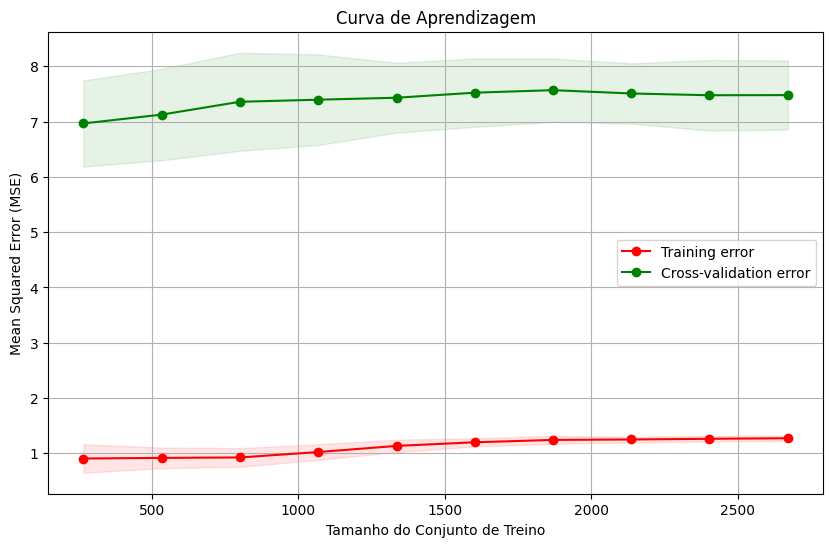

In [ ]:
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve

# Gerar dados para a curva de aprendizagem
train_sizes, train_scores, test_scores = learning_curve(
    estimator=model,  # O modelo treinado
    X=X_train,
    y=y_train.values.ravel(), # .values.ravel() para garantir o formato correto
    train_sizes=np.linspace(0.1, 1.0, 10), # Usar 10 pontos entre 10% e 100% do treino
    cv=5,  # Validacao cruzada com 5 folds
    scoring='neg_mean_squared_error', # Usar MSE (negativo para scikit-learn)
    random_state=42
)

# Converter scores para positivo MSE
train_mse = -train_scores
test_mse = -test_scores

# Calcular as médias e desvios padrão dos scores
train_scores_mean = np.mean(train_mse, axis=1)
train_scores_std = np.std(train_mse, axis=1)
test_scores_mean = np.mean(test_mse, axis=1)
test_scores_std = np.std(test_mse, axis=1)

# Plotar a curva de aprendizagem
plt.figure(figsize=(10, 6))
plt.fill_between(train_sizes, train_scores_mean - train_scores_std,
                 train_scores_mean + train_scores_std, alpha=0.1, color="r")
plt.fill_between(train_sizes, test_scores_mean - test_scores_std,
                 test_scores_mean + test_scores_std, alpha=0.1, color="g")
plt.plot(train_sizes, train_scores_mean, 'o-', color="r", label="Training error")
plt.plot(train_sizes, test_scores_mean, 'o-', color="g", label="Cross-validation error")

plt.title("Curva de Aprendizagem")
plt.xlabel("Tamanho do Conjunto de Treino")
plt.ylabel("Mean Squared Error (MSE)")
plt.legend(loc="best")
plt.grid()
plt.show()